# Fase 1 — Análise exploratória Olist

Sete blocos, na ordem do escopo. Para gerar gráficos no terminal:
`python notebooks/01_analise_exploratoria.py` (rode na raiz do repositório).

O notebook é gerado por `python scripts/gerar_notebook.py`.


## Bloco 1 — Dicionário e ligações

O pedido é o centro. `customer_id` é por compra; `customer_unique_id` é a pessoa.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ORDERS_CSV = "olist_orders_dataset.csv"


def find_root() -> Path:
    starts = [Path.cwd().resolve()]
    nb = globals().get("__vsc_ipynb_file__")
    if nb:
        starts.append(Path(nb).resolve().parent)
    seen = set()
    for start in starts:
        for folder in (start, *start.parents):
            if folder in seen:
                continue
            seen.add(folder)
            if (folder / "data" / "raw" / ORDERS_CSV).exists():
                return folder
    raise FileNotFoundError(
        "Não achei data/raw/olist_orders_dataset.csv. "
        "Coloque os CSVs da Olist em data/raw/ (veja data/raw/README.md)."
    )


ROOT = find_root()
DATA = ROOT / "data" / "raw"
print("pasta de trabalho:", Path.cwd())
print("lendo de", DATA)

orders = pd.read_csv(DATA / ORDERS_CSV, parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_csv(DATA / "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA / "olist_order_reviews_dataset.csv")
customers = pd.read_csv(DATA / "olist_customers_dataset.csv")
products = pd.read_csv(DATA / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA / "olist_sellers_dataset.csv")

for name, df in [("orders", orders), ("items", items), ("payments", payments),
                 ("reviews", reviews), ("customers", customers),
                 ("products", products), ("sellers", sellers)]:
    print(f"{name:12} {len(df):>8,}  {list(df.columns)}")


pasta de trabalho: d:\ESTUDO\PÓS AGENTES DE INTELIGÊNCIA ARTIFICIAL - FIAP\00. TECH CHALLENGE\olist-intelligent-marketplace\notebooks
lendo de D:\ESTUDO\PÓS AGENTES DE INTELIGÊNCIA ARTIFICIAL - FIAP\00. TECH CHALLENGE\olist-intelligent-marketplace\data\raw
orders         99,441  ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
items         112,650  ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
payments      103,886  ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
reviews        99,224  ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
customers      99,441  ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_sta

## Bloco 2 — Operação do pedido


2016-09-04 21:15:19 → 2018-10-17 17:30:18
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Entregues: 96,478 | % atraso: 6.77%
Mediana atraso (atrasados): 7 dias
                    n    pct
customer_state              
CE               1279  13.76
BA               3256  12.16
RJ              12350  12.11
ES               1995  10.73
PE               1593   9.60
SC               3546   8.21
GO               1957   6.54
RS               5345   6.08


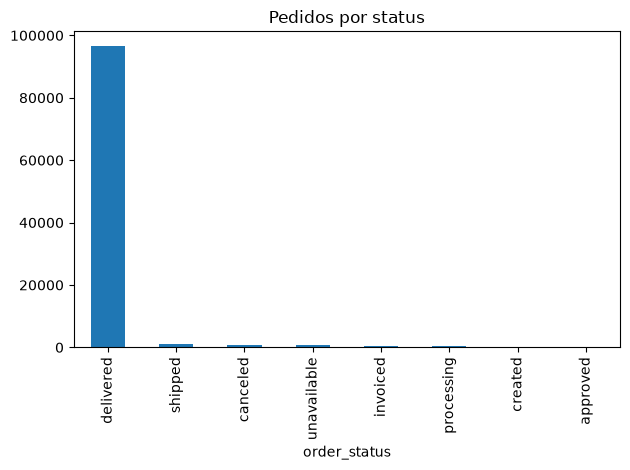

In [2]:
print(orders.order_purchase_timestamp.min(), "→", orders.order_purchase_timestamp.max())
print(orders.order_status.value_counts())
delivered = orders[orders.order_status == "delivered"].copy()
delivered["atraso_dias"] = (
    delivered.order_delivered_customer_date - delivered.order_estimated_delivery_date
).dt.days
late = delivered.atraso_dias > 0
print(f"Entregues: {len(delivered):,} | % atraso: {late.mean()*100:.2f}%")
print(f"Mediana atraso (atrasados): {delivered.loc[late, 'atraso_dias'].median():.0f} dias")
oc = delivered.merge(customers, on="customer_id")
oc["atrasado"] = oc.atraso_dias > 0
by = oc.groupby("customer_state").agg(n=("order_id", "count"), pct=("atrasado", "mean"))
print((by[by.n >= 1000].assign(pct=lambda d: d.pct * 100).sort_values("pct", ascending=False).head(8).round(2)))
orders.order_status.value_counts().plot(kind="bar", title="Pedidos por status")
plt.tight_layout()


## Bloco 3 — Dinheiro e item


GMV R$ 13,591,644 | frete R$ 2,251,910 (16.6% do GMV)
Ticket médio 137.75 | mediana 86.90
payment_type
credit_card    73.9
boleto         19.0
voucher         5.6
debit_card      1.5
not_defined     0.0
Name: proportion, dtype: float64


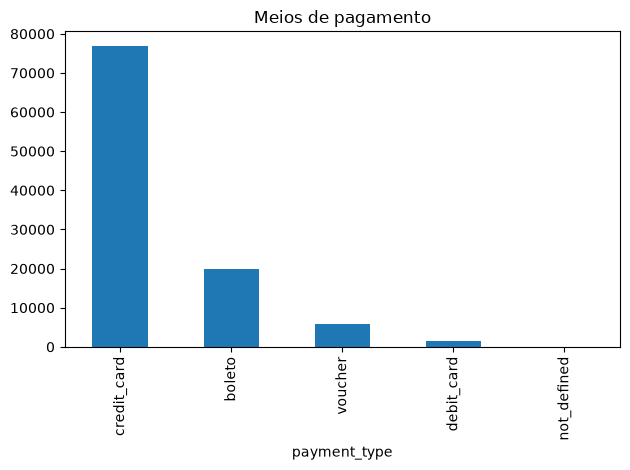

In [3]:
gmv, frete = items.price.sum(), items.freight_value.sum()
print(f"GMV R$ {gmv:,.0f} | frete R$ {frete:,.0f} ({frete/gmv*100:.1f}% do GMV)")
pp = items.groupby("order_id").price.sum()
print(f"Ticket médio {pp.mean():.2f} | mediana {pp.median():.2f}")
print((payments.payment_type.value_counts(normalize=True) * 100).round(1))
payments.payment_type.value_counts().plot(kind="bar", title="Meios de pagamento")
plt.tight_layout()


## Bloco 4 — Experiência (reviews)


review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: proportion, dtype: float64
nota média 4.09
% notas 1-2 14.7
% com texto 41.3
nota no prazo 4.29
nota atrasado 2.57
% 1-2 atrasado 54.0


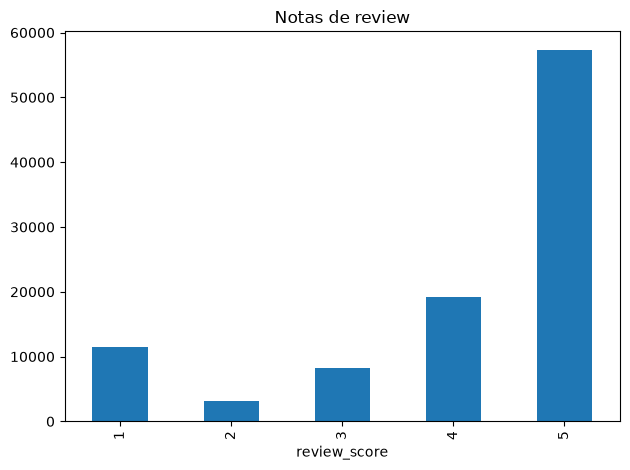

In [4]:
print((reviews.review_score.value_counts(normalize=True).sort_index() * 100).round(1))
print("nota média", round(reviews.review_score.mean(), 2))
print("% notas 1-2", round((reviews.review_score <= 2).mean() * 100, 1))
print("% com texto", round(reviews.review_comment_message.notna().mean() * 100, 1))
rev = reviews.merge(
    orders[["order_id", "order_status", "order_delivered_customer_date", "order_estimated_delivery_date"]],
    on="order_id",
)
d = rev[rev.order_status == "delivered"].copy()
d["atrasado"] = d.order_delivered_customer_date > d.order_estimated_delivery_date
print("nota no prazo", round(d.loc[~d.atrasado, "review_score"].mean(), 2))
print("nota atrasado", round(d.loc[d.atrasado, "review_score"].mean(), 2))
print("% 1-2 atrasado", round((d.loc[d.atrasado, "review_score"] <= 2).mean() * 100, 1))
reviews.review_score.value_counts().sort_index().plot(kind="bar", title="Notas de review")
plt.tight_layout()


## Bloco 5 — Cliente e retenção


In [5]:
vc = orders.merge(customers, on="customer_id").groupby("customer_unique_id").order_id.nunique()
print("clientes", f"{vc.size:,}", "| % um pedido", round((vc == 1).mean() * 100, 2))
print((customers.customer_state.value_counts(normalize=True).head(5) * 100).round(1))


clientes 96,096 | % um pedido 96.88
customer_state
SP    42.0
RJ    12.9
MG    11.7
RS     5.5
PR     5.1
Name: proportion, dtype: float64


## Bloco 6 — Oferta


In [6]:
print("produtos", len(products), "categorias", products.product_category_name.nunique(), "sellers", len(sellers))
itp = items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
cat = itp.groupby("product_category_name").price.sum().sort_values(ascending=False)
print(cat.head(10).round(0))
print("top 10 % GMV", round(cat.head(10).sum() / cat.sum() * 100, 1))


produtos 32951 categorias 73 sellers 3095
product_category_name
beleza_saude              1258681.0
relogios_presentes        1205006.0
cama_mesa_banho           1036989.0
esporte_lazer              988049.0
informatica_acessorios     911954.0
moveis_decoracao           729762.0
cool_stuff                 635291.0
utilidades_domesticas      632249.0
automotivo                 592720.0
ferramentas_jardim         485256.0
Name: price, dtype: float64
top 10 % GMV 63.2


## Bloco 7 — Síntese

1. Atraso raro, nota destruída (2,57 vs 4,29).
2. Reviews ruins + texto para classificar.
3. 96,9% compram uma vez.
4. Frete relevante; não vira agente próprio nesta fase.
5. Cancelados com nota ~1,8.

Priorização e agentes: pasta `docs/`.
